In [1]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

In [2]:
tickers = [
    # Core
    "INTC","AAPL","MSFT","NVDA","AMD",
    "CSCO","IBM","ORCL","TXN","QCOM",
    "AVGO","ADBE","CRM","AMAT","MU",

    # Software / Cloud
    "NOW","PANW","SNPS","CDNS","WDAY",
    "FTNT","TEAM","ZS","OKTA","CRWD",

    # Semiconductor
    "LRCX","KLAC","NXPI","MCHP","MRVL",
    "SWKS","ADI","ON","TER",

    # Hardware / Systems
    "HPQ","DELL","HPE",

    # Platforms
    "META","GOOGL"
]
print(f"Total tickers in sample: {len(tickers)}")

Total tickers in sample: 39


In [3]:
start_date = "2010-01-01"
end_date = "2025-01-01"

all_data = []
dropped_log = {}

for ticker in tickers:
    stock = yf.Ticker(ticker)
    hist = stock.history(start=start_date, end=end_date)

    if hist.empty:
        dropped_log[ticker] = "No price data returned by Yahoo Finance"
        continue

    # Annual aggregation using entire year
    annual = pd.DataFrame()
    annual["High"] = hist["High"].resample("A").max()
    annual["Low"] = hist["Low"].resample("A").min()
    annual["Close"] = hist["Close"].resample("A").last()
    annual["Volume"] = hist["Volume"].resample("A").sum()
    annual["Year"] = annual.index.year

    dividends = stock.dividends.resample("A").sum()
    dividends = dividends.to_frame(name="Dividend")
    dividends["Year"] = dividends.index.year

    df = pd.merge(annual, dividends, on="Year", how="left")

    # Market-based proxy features
    df["Price_Momentum"] = df["Close"].pct_change()
    df["Price_Range_Ratio"] = df["High"] / df["Low"]
    df["Volume_Momentum"] = df["Volume"].pct_change()

    df["Ticker"] = ticker

    all_data.append(df[[
        "Ticker","Year",
        "Price_Momentum",
        "Price_Range_Ratio",
        "Volume_Momentum",
        "Dividend"
    ]])

    n_rows = len(df)
    n_nan = df[["Price_Momentum","Price_Range_Ratio","Volume_Momentum","Dividend"]].isna().any(axis=1).sum()
    if n_nan > 0:
        dropped_log[ticker] = f"{n_nan} of {n_rows} rows dropped due to NaN"

data = pd.concat(all_data, ignore_index=True)
data = data.sort_values(["Ticker","Year"]).reset_index(drop=True)

# Genuine future prediction: shift dividend forward by one year per company
data["Next_Dividend"] = data.groupby("Ticker")["Dividend"].shift(-1)
data = data.dropna(subset=["Next_Dividend"])
data["Target"] = (data["Next_Dividend"] > data["Dividend"]).astype(int)
data = data.drop(columns=["Next_Dividend"])

In [4]:
print(f"Rows before dropna: {len(data)}")
print(f"Companies before dropna: {data['Ticker'].nunique()}")

nan_by_ticker = data.groupby("Ticker")[["Price_Momentum","Price_Range_Ratio","Volume_Momentum","Target"]].apply(
    lambda g: g.isna().any(axis=1).sum()
)
nan_by_ticker = nan_by_ticker[nan_by_ticker > 0]
if len(nan_by_ticker) > 0:
    print("\nRows with NaN per company (before dropna):")
    print(nan_by_ticker.to_string())

Rows before dropna: 291
Companies before dropna: 26

Rows with NaN per company (before dropna):
Ticker
AAPL    1
ADI     1
AMAT    1
AVGO    1
CSCO    1
HPE     1
HPQ     1
IBM     1
INTC    1
KLAC    1
MCHP    1
MSFT    1
MU      1
ORCL    1
QCOM    1
TXN     1


In [5]:
data_clean = data.dropna(subset=["Price_Momentum","Price_Range_Ratio","Volume_Momentum","Target"]).copy()
data_clean["Target"] = data_clean["Target"].astype(int)

In [6]:
# Per-company attrition: consistent NaN count on the exported columns only
feature_cols = ["Price_Momentum","Price_Range_Ratio","Volume_Momentum"]
all_rows = data.groupby("Ticker").size().rename("Total_Rows")
nan_rows = data.groupby("Ticker")[feature_cols + ["Target"]].apply(
    lambda g: g.isna().any(axis=1).sum()
).rename("NaN_Rows")
clean_rows = data_clean.groupby("Ticker").size().rename("Clean_Rows")

attrition = pd.concat([all_rows, nan_rows, clean_rows], axis=1).fillna(0).astype(int)
attrition["Removed"] = attrition["Total_Rows"] - attrition["Clean_Rows"]
attrition = attrition.sort_values("Removed", ascending=False)

print("PER-COMPANY ATTRITION TABLE")
print("=" * 70)
print(attrition.to_string())
print(f"\nCompanies fully removed (0 clean rows): {(attrition['Clean_Rows'] == 0).sum()}")
print(f"Companies partially reduced: {((attrition['Clean_Rows'] > 0) & (attrition['Removed'] > 0)).sum()}")
print(f"Companies unchanged: {(attrition['Removed'] == 0).sum()}")

PER-COMPANY ATTRITION TABLE
        Total_Rows  NaN_Rows  Clean_Rows  Removed
Ticker                                           
AAPL            14         1          13        1
IBM             14         1          13        1
QCOM            14         1          13        1
ORCL            14         1          13        1
MU              14         1          13        1
MSFT            14         1          13        1
MCHP            14         1          13        1
ADI             14         1          13        1
KLAC            14         1          13        1
INTC            14         1          13        1
TXN             14         1          13        1
HPQ             14         1          13        1
HPE              9         1           8        1
CSCO            14         1          13        1
AVGO            14         1          13        1
AMAT            14         1          13        1
GOOGL            1         0           1        0
DELL             3    

In [7]:
survived = sorted(data_clean["Ticker"].unique().tolist())
removed = sorted([t for t in tickers if t not in survived])

print(f"Total tickers:          {len(tickers)}")
print(f"Survived:               {len(survived)} companies")
print(f"Removed:                {len(removed)} companies — {removed}")
print(f"\nFinal dataset size:     {len(data_clean)} observations, {data_clean['Ticker'].nunique()} companies")
print(f"Year range:             {data_clean['Year'].min()} – {data_clean['Year'].max()}")
print(f"Avg obs per company:    {len(data_clean) / data_clean['Ticker'].nunique():.1f}")

Total tickers:          39
Survived:               26 companies
Removed:                13 companies — ['ADBE', 'AMD', 'CDNS', 'CRWD', 'FTNT', 'NOW', 'OKTA', 'ON', 'PANW', 'SNPS', 'TEAM', 'WDAY', 'ZS']

Final dataset size:     275 observations, 26 companies
Year range:             2011 – 2023
Avg obs per company:    10.6


In [8]:
# Fully removed companies (none in this run — all 39 survived)
print("COMPANY REMOVAL SUMMARY")
print("=" * 60)
if len(removed) == 0:
    print("  No companies were fully removed. All 39 survived dropna.")
else:
    for ticker in removed:
        reason = dropped_log.get(ticker, "No dividend data or insufficient history")
        print(f"  {ticker:6s} -> {reason}")

# Companies with partial data loss (lost some years but not all)
partial = attrition[(attrition["Clean_Rows"] > 0) & (attrition["Removed"] > 0)]
if len(partial) > 0:
    print(f"\nPARTIAL DATA LOSS ({len(partial)} companies lost rows):")
    print("=" * 60)
    for ticker, row in partial.iterrows():
        print(f"  {ticker:6s} -> {row['Total_Rows']} total, {row['NaN_Rows']} NaN, {row['Clean_Rows']} kept")
else:
    print("\nNo partial data loss — all companies retained the same number of rows.")

COMPANY REMOVAL SUMMARY
  ADBE   -> 15 of 15 rows dropped due to NaN
  AMD    -> 15 of 15 rows dropped due to NaN
  CDNS   -> 15 of 15 rows dropped due to NaN
  CRWD   -> 6 of 6 rows dropped due to NaN
  FTNT   -> 15 of 15 rows dropped due to NaN
  NOW    -> 13 of 13 rows dropped due to NaN
  OKTA   -> 8 of 8 rows dropped due to NaN
  ON     -> 15 of 15 rows dropped due to NaN
  PANW   -> 13 of 13 rows dropped due to NaN
  SNPS   -> 15 of 15 rows dropped due to NaN
  TEAM   -> 10 of 10 rows dropped due to NaN
  WDAY   -> 13 of 13 rows dropped due to NaN
  ZS     -> 7 of 7 rows dropped due to NaN

PARTIAL DATA LOSS (16 companies lost rows):
  AAPL   -> 14 total, 1 NaN, 13 kept
  IBM    -> 14 total, 1 NaN, 13 kept
  QCOM   -> 14 total, 1 NaN, 13 kept
  ORCL   -> 14 total, 1 NaN, 13 kept
  MU     -> 14 total, 1 NaN, 13 kept
  MSFT   -> 14 total, 1 NaN, 13 kept
  MCHP   -> 14 total, 1 NaN, 13 kept
  ADI    -> 14 total, 1 NaN, 13 kept
  KLAC   -> 14 total, 1 NaN, 13 kept
  INTC   -> 14 tota

In [9]:
class_counts = data_clean["Target"].value_counts()
class_pct = data_clean["Target"].value_counts(normalize=True) * 100

print("Target Class Distribution:")
print(f"  Dividend Increase (1): {class_counts[1]} ({class_pct[1]:.1f}%)")
print(f"  No Increase      (0): {class_counts[0]} ({class_pct[0]:.1f}%)")
print(f"  Imbalance ratio:       {class_counts[1]/class_counts[0]:.1f}:1")
print("\nNote: Basic accuracy would be misleading. A model predicting 'Increase'")
print("for every observation would achieve ~85% accuracy. To address this imbalance,")
print("the modelling notebook applies SMOTE (Synthetic Minority Over-sampling Technique)")
print("on the training set and reports precision, recall, F1, balanced accuracy, and confusion matrix.")

Target Class Distribution:
  Dividend Increase (1): 225 (81.8%)
  No Increase      (0): 50 (18.2%)
  Imbalance ratio:       4.5:1

Note: Basic accuracy would be misleading. A model predicting 'Increase'
for every observation would achieve ~85% accuracy. To address this imbalance,
the modelling notebook applies SMOTE (Synthetic Minority Over-sampling Technique)
on the training set and reports precision, recall, F1, balanced accuracy, and confusion matrix.


OBSERVATIONS PER YEAR
      No Increase (0)  Increase (1)
Year                               
2011                3            14
2012                2            15
2013                6            14
2014                4            16
2015                4            16
2016                3            18
2017                3            19
2018                4            18
2019                3            19
2020                4            18
2021                3            20
2022                4            19
2023                7            19

Total observations: 275


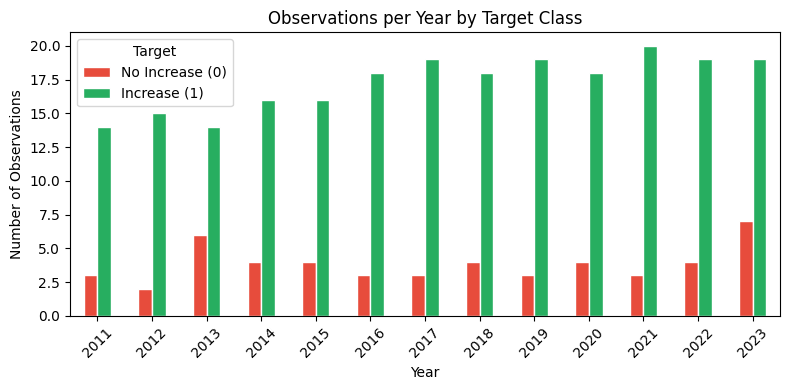

In [10]:
# Per-year observation counts
year_counts = data_clean.groupby("Year").size()
year_class = data_clean.groupby(["Year", "Target"]).size().unstack(fill_value=0)
year_class.columns = ["No Increase (0)", "Increase (1)"]

print("OBSERVATIONS PER YEAR")
print("=" * 50)
print(year_class.to_string())
print(f"\nTotal observations: {len(data_clean)}")

# Bar chart
fig, ax = plt.subplots(figsize=(8, 4))
year_class.plot(kind="bar", ax=ax, color=["#e74c3c", "#27ae60"], edgecolor="white")
ax.set_title("Observations per Year by Target Class")
ax.set_xlabel("Year")
ax.set_ylabel("Number of Observations")
ax.legend(title="Target")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [11]:
# Per-company summary: year range and observation count
company_summary = data_clean.groupby("Ticker").agg(
    First_Year=("Year", "min"),
    Last_Year=("Year", "max"),
    Observations=("Year", "size")
).sort_values("Ticker")

print("PER-COMPANY SUMMARY (surviving companies only)")
print("=" * 55)
print(company_summary.to_string())

PER-COMPANY SUMMARY (surviving companies only)
        First_Year  Last_Year  Observations
Ticker                                     
AAPL          2011       2023            13
ADI           2011       2023            13
AMAT          2011       2023            13
AVGO          2011       2023            13
CRM           2023       2023             1
CSCO          2011       2023            13
DELL          2021       2023             3
GOOGL         2023       2023             1
HPE           2016       2023             8
HPQ           2011       2023            13
IBM           2011       2023            13
INTC          2011       2023            13
KLAC          2011       2023            13
LRCX          2013       2023            11
MCHP          2011       2023            13
META          2023       2023             1
MRVL          2011       2023            13
MSFT          2011       2023            13
MU            2011       2023            13
NVDA          2011       2023

In [12]:

export_cols = ["Ticker", "Year", "Price_Momentum", "Price_Range_Ratio", "Volume_Momentum", "Target"]
data_clean[export_cols].to_csv("dividend_dataset.csv", index=False)

print("Dataset saved successfully as 'dividend_dataset.csv'")
print(f"  Shape: {data_clean[export_cols].shape}")
print(f"  Columns: {export_cols}")

Dataset saved successfully as 'dividend_dataset.csv'
  Shape: (275, 6)
  Columns: ['Ticker', 'Year', 'Price_Momentum', 'Price_Range_Ratio', 'Volume_Momentum', 'Target']
